In [1]:
import importlib
import inspect
import os
from argparse import Namespace
import numpy as np

%load_ext autoreload
%autoreload 2



def get_all_dataset_names():
    return [
        dataset.split(".")[0]
        for dataset in os.listdir("dataset")
        if not dataset.find("__") > -1 and "py" in dataset
    ]


def get_all_datasets():
    datasets = {}
    for dataset in get_all_dataset_names():
        mod = importlib.import_module("dataset." + dataset)
        dataset_classes_name = [
            x
            for x in mod.__dir__()
            if "type" in str(type(getattr(mod, x)))
            and "DatasetBase" in str(inspect.getmro(getattr(mod, x))[1:])
        ]
        for d in dataset_classes_name:
            c = getattr(mod, d)
            datasets[c.NAME] = c
    return datasets


def get_dataset(dataset_name, accelerator, args: Namespace):
    """
    Returns the dataset object.
    """
    datasets_set = get_all_datasets()
    assert (
        dataset_name in datasets_set
    ), f"Dataset {dataset_name} not found. Available datasets: {datasets_set.keys()}"
    return datasets_set[dataset_name](accelerator, args)


In [5]:
from accelerate import Accelerator
accelerator = Accelerator()

# Configure args for Qwen2 model and dataset
args = Namespace()
args.model = "Qwen/Qwen2.5-0.5B"  # Using smaller Qwen2 model for testing
args.dataset = "MMLU-chem"  # Boolean Questions dataset (2-class classification)
args.add_space = False
args.max_seq_len = 300
args.batch_size = 4
args.is_s2s = False  # Qwen2 is decoder-only, not sequence-to-sequence
args.testing_set = "val"

print(f"Using model: {args.model}")
print(f"Using dataset: {args.dataset}")
# Create the dataset
try:
    dataset = get_all_datasets()['mcdataset'](accelerator, args)
    print(f"✅ Successfully created dataset with {dataset.num_labels} labels")
    
    # Get the dataloaders
    dataset.get_loaders()
    print(f"✅ Successfully created dataloaders")
    print(f"📊 Number of training samples: {dataset.num_samples}")
    print(f"🎯 Target token IDs: {dataset.target_ids}")
    
except Exception as e:
    print(f"❌ Error creating dataset: {e}")
    print("Available datasets:", list(get_all_datasets().keys()))

Using model: Qwen/Qwen2.5-0.5B
Using dataset: MMLU-chem
Loaded MMLU-chem dataset.
✅ Successfully created dataset with 4 labels
✅ Successfully created dataloaders
📊 Number of training samples: 100
🎯 Target token IDs: tensor([[32],
        [33],
        [34],
        [35]])


In [133]:
next(iter(dataset.train_dataloader))

({'input_ids': tensor([[151643, 151643, 151643,  ...,    198,  16141,     25],
         [151643, 151643, 151643,  ...,    198,  16141,     25],
         [151643, 151643, 151643,  ...,    198,  16141,     25],
         [151643, 151643, 151643,  ...,    624,  16141,     25]]), 'attention_mask': tensor([[0, 0, 0,  ..., 1, 1, 1],
         [0, 0, 0,  ..., 1, 1, 1],
         [0, 0, 0,  ..., 1, 1, 1],
         [0, 0, 0,  ..., 1, 1, 1]])},
 tensor([3, 2, 3, 1]),
 tensor([35, 34, 35, 33]))

In [ ]:
next(iter(dataset.test_dataloader))


({'input_ids': tensor([[151643, 151643, 151643,  ...,    198,  16141,     25],
         [151643, 151643, 151643,  ...,    198,  16141,     25],
         [151643, 151643, 151643,  ...,    198,  16141,     25],
         [151643, 151643, 151643,  ...,    624,  16141,     25]]), 'attention_mask': tensor([[0, 0, 0,  ..., 1, 1, 1],
         [0, 0, 0,  ..., 1, 1, 1],
         [0, 0, 0,  ..., 1, 1, 1],
         [0, 0, 0,  ..., 1, 1, 1]])},
 tensor([3, 2, 3, 1]),
 tensor([35, 34, 35, 33]))

In [105]:
# Explore the dataset structure
if 'dataset' in locals():
    print("=== Dataset Information ===")
    print(f"Dataset type: {type(dataset)}")
    print(f"Number of labels: {dataset.num_labels}")
    print(f"Tokenizer: {type(dataset.tokenizer)}")
    print(f"Tokenizer vocab size: {dataset.tokenizer.vocab_size}")
    
    # Check special tokens
    print("\n=== Special Tokens ===")
    print(f"BOS token: '{dataset.tokenizer.bos_token}' (ID: {dataset.tokenizer.bos_token_id})")
    print(f"EOS token: '{dataset.tokenizer.eos_token}' (ID: {dataset.tokenizer.eos_token_id})")
    print(f"PAD token: '{dataset.tokenizer.pad_token}' (ID: {dataset.tokenizer.pad_token_id})")
    print(f"UNK token: '{dataset.tokenizer.unk_token}' (ID: {dataset.tokenizer.unk_token_id})")
    
    # Target tokens for classification
    print(f"\n=== Target Tokens for Classification ===")
    print(f"Target IDs shape: {dataset.target_ids.shape}")
    print(f"Target token IDs: {dataset.target_ids.tolist()}")
    
    # Decode target tokens
    for i, target_id in enumerate(dataset.target_ids):
        decoded = dataset.tokenizer.decode(target_id, skip_special_tokens=True)
        print(f"Label {i}: token_id={target_id.item()} -> '{decoded}'")
    
    # Show a sample batch from train dataloader
    print("\n=== Sample Training Batch ===")
    try:
        sample_batch = next(iter(dataset.train_dataloader))
        print(f"Batch type: {type(sample_batch)}")
        print(f"Batch length: {len(sample_batch)}")
        
        # Handle BatchEncoding object
        batch_encoding = sample_batch[0]
        labels = sample_batch[1] if len(sample_batch) > 1 else None
        extra = sample_batch[2] if len(sample_batch) > 2 else None
        
        print(f"\nBatchEncoding keys: {list(batch_encoding.keys())}")
        
        # Get input_ids and attention_mask
        input_ids = batch_encoding['input_ids']
        attention_mask = batch_encoding.get('attention_mask', None)
        
        print(f"Input IDs shape: {input_ids.shape}")
        if attention_mask is not None:
            print(f"Attention mask shape: {attention_mask.shape}")
        if labels is not None:
            print(f"Labels shape: {labels.shape}")
            print(f"Sample labels: {labels[:5].tolist()}")
        if extra is not None:
            print(f"Extra tensor shape: {extra.shape}")
        
        # Show first sample
        print(f"\nFirst sample input IDs (first 20): {input_ids[0][:20].tolist()}")
        if attention_mask is not None:
            print(f"First sample attention mask (first 20): {attention_mask[0][:20].tolist()}")
        
        # Decode first sample
        decoded_text = dataset.tokenizer.decode(input_ids[0], skip_special_tokens=False)
        print(f"\nDecoded sample:\n{decoded_text}...")
        
        # Show the actual length vs padded length
        actual_length = attention_mask[0].sum().item() if attention_mask is not None else len(input_ids[0])
        print(f"\nSequence info:")
        print(f"Total length: {len(input_ids[0])}")
        print(f"Actual length (non-padded): {actual_length}")
        
    except Exception as e:
        print(f"Error exploring batch: {e}")
        import traceback
        traceback.print_exc()
else:
    print("❌ Dataset not created yet. Run the previous cell first.")

=== Dataset Information ===
Dataset type: <class 'dataset.S2SDataset_Classification.S2SDataset_Classification'>
Number of labels: 2
Tokenizer: <class 'transformers.models.qwen2.tokenization_qwen2_fast.Qwen2TokenizerFast'>
Tokenizer vocab size: 151643

=== Special Tokens ===
BOS token: 'None' (ID: None)
EOS token: '<|endoftext|>' (ID: 151643)
PAD token: '<|endoftext|>' (ID: 151643)
UNK token: 'None' (ID: None)

=== Target Tokens for Classification ===
Target IDs shape: torch.Size([2, 1])
Target token IDs: [[2514], [4049]]
Label 0: token_id=2514 -> 'True'
Label 1: token_id=4049 -> 'False'

=== Sample Training Batch ===
Batch type: <class 'tuple'>
Batch length: 3

BatchEncoding keys: ['input_ids', 'attention_mask']
Input IDs shape: torch.Size([4, 300])
Attention mask shape: torch.Size([4, 300])
Labels shape: torch.Size([4])
Sample labels: [1, 1, 1, 1]
Extra tensor shape: torch.Size([4])

First sample input IDs (first 20): [151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 15

In [103]:
sample_batch, label, target_id = next(iter(dataset.train_dataloader))
print(sample_batch['input_ids'].shape)
print(sample_batch['attention_mask'].shape)
print(label)
print(target_id)

torch.Size([4, 300])
torch.Size([4, 300])
tensor([1, 1, 1, 1])
tensor([4049, 4049, 4049, 4049])


In [72]:
dataset.tokenizer("False")

{'input_ids': [4049], 'attention_mask': [1]}

In [ ]:
# Show actual content without padding
if 'dataset' in locals():
    print("=== Dataset Content Analysis ===")
    
    # Get a batch
    sample_batch = next(iter(dataset.train_dataloader))
    batch_encoding = sample_batch[0]
    labels = sample_batch[1]
    
    input_ids = batch_encoding['input_ids']
    attention_mask = batch_encoding['attention_mask']
    
    # Show actual content (where attention_mask = 1)
    for i in range(min(3, len(input_ids))):  # Show first 3 samples
        print(f"\n=== Sample {i+1} ===")
        print(f"Label: {labels[i].item()}")
        
        # Find the actual content (non-padded)
        mask = attention_mask[i]
        actual_tokens = input_ids[i][mask == 1]
        
        print(f"Actual sequence length: {len(actual_tokens)}")
        print(f"Token IDs: {actual_tokens[:15].tolist()}...")
        
        # Decode the actual content
        actual_text = dataset.tokenizer.decode(actual_tokens, skip_special_tokens=True)
        print(f"Decoded text: {actual_text[:200]}...")
        
        # Check if this is a True/False question by looking for the target tokens
        target_true = dataset.target_ids[0].item()  # 3007 for " True"
        target_false = dataset.target_ids[1].item()  # 3557 for " False"
        
        if target_true in actual_tokens:
            print(f"✅ Contains ' True' token ({target_true})")
        if target_false in actual_tokens:
            print(f"❌ Contains ' False' token ({target_false})")

    print(f"\n=== Dataloader Summary ===")
    print(f"✅ Successfully created Qwen2 dataset for BoolQ")
    print(f"📊 Training samples: {dataset.num_samples}")
    print(f"🏷️ Labels: 2 (True/False)")
    print(f"📝 Batch size: {args.batch_size}")
    print(f"📏 Max sequence length: {args.max_seq_len}")
    print(f"🎯 Target tokens: {dataset.target_ids.squeeze().tolist()} -> [' True', ' False']")

=== Dataset Content Analysis ===

=== Sample 1 ===
Label: 1
Actual sequence length: 188
Token IDs: [4418, 279, 21085, 3685, 323, 4226, 279, 3405, 448, 279, 4244, 364, 1866, 6, 476]...
Decoded text: Read the passage below and answer the question with the words 'true' or 'false'.

Passage: Persian (/ˈpɜːrʒən, -ʃən/), also known by its endonym Farsi (فارسی fārsi (fɒːɾˈsiː) ( listen)), is one of the...

=== Sample 2 ===
Label: 1
Actual sequence length: 201
Token IDs: [4418, 279, 21085, 3685, 323, 4226, 279, 3405, 448, 279, 4244, 364, 1866, 6, 476]...
Decoded text: Read the passage below and answer the question with the words 'true' or 'false'.

Passage: Good Samaritan laws offer legal protection to people who give reasonable assistance to those who are, or who ...

=== Sample 3 ===
Label: 1
Actual sequence length: 100
Token IDs: [4418, 279, 21085, 3685, 323, 4226, 279, 3405, 448, 279, 4244, 364, 1866, 6, 476]...
Decoded text: Read the passage below and answer the question with the words 't

### run with stored dataset

In [2]:
from src.qwen_jax import load_params_and_config, QwenForCausalLM
import jax
import jax.numpy as jnp
import numpy as np

%load_ext autoreload
%autoreload 2

params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B")
jax_model = QwenForCausalLM(**config)
params

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


FrozenDict({
    params: {
        embed_tokens: {
            embedding: Array([[-1.007e-02,  4.199e-02,  9.888e-03, ...,  9.949e-03,  1.514e-02,
                    -7.050e-03],
                   [-1.465e-02,  6.032e-05, -1.843e-02, ..., -1.694e-03,  3.113e-03,
                    -8.423e-03],
                   [-3.662e-02, -9.827e-03,  6.989e-03, ..., -7.751e-03, -1.709e-02,
                    -1.049e-04],
                   ...,
                   [ 2.777e-03, -9.399e-03,  4.242e-03, ..., -6.561e-03, -1.062e-02,
                     1.721e-02],
                   [ 2.777e-03, -9.399e-03,  4.242e-03, ..., -6.561e-03, -1.062e-02,
                     1.721e-02],
                   [ 2.777e-03, -9.399e-03,  4.242e-03, ..., -6.561e-03, -1.062e-02,
                     1.721e-02]], dtype=float16),
        },
        layers_0: {
            input_layernorm: {
                weight: Array([-0.04614,  0.0437 , -0.02441,  0.0825 , -0.04102,  0.0376 ,
                       -0.0398 , -0.

In [3]:
with np.load("datasets/text_classification/winogrande_m/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((2556, 300), (2556, 300), (2556,), (2556,))

In [4]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs, inter = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False, mutable=['intermediates'])
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0][-1])

Forward pass output shape: (4, 300, 151936)
Sample [ 6.156 -0.712  2.795 ... -3.092 -3.092 -3.092]


In [5]:
inter['intermediates']['layers_0']['self_attn']['attn_weights_masked'][0].shape

(4, 14, 300, 300)

In [ ]:
arr = inter['intermediates']['layers_0']['self_attn']['attn_weights_masked'][0][0, 0, 250:260, 250:260]
arr = np.array(arr)
print(f"{np.array2string(arr, precision=2)}")

[[ -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf 157.9  -inf  -inf  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf 131.5 130.8  -inf  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf 158.8 158.6 158.1  -inf  -inf  -inf]
 [ -inf  -inf  -inf  -inf 132.2 132.5 131.9 130.9  -inf  -inf]
 [ -inf  -inf  -inf  -inf 130.9 131.6 130.6 130.9 130.8  -inf]
 [ -inf  -inf  -inf  -inf 155.  155.2 154.9 155.5 155.8 155.1]]


In [ ]:
arr = inter['intermediates']['layers_0']['self_attn']['attn_weights_prob'][0][0, 0, 250:260, 250:260]
arr = np.array(arr)
print(f"{np.array2string(arr, precision=2)}")

[[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   1.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.68 0.32 0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.41 0.36 0.22 0.   0.   0.  ]
 [0.   0.   0.   0.   0.31 0.4  0.21 0.08 0.   0.  ]
 [0.   0.   0.   0.   0.17 0.37 0.13 0.17 0.15 0.  ]
 [0.   0.   0.   0.   0.12 0.16 0.11 0.2  0.26 0.14]]


In [8]:
# Test forward pass with loaded Qwen model and dataset batch
# Assumes: jax_model, params, input_ids, attention_mask are already defined

# Forward pass (no gradient, inference mode)
outputs = jax_model.apply(params, input_ids[:4], attention_mask[:4], train=False)
print("Forward pass output shape:", outputs.shape)
print("Sample", outputs[0, -1])

Forward pass output shape: (4, 300, 151936)
Sample [ 6.156 -0.712  2.795 ... -3.092 -3.092 -3.092]


In [9]:
selected = jnp.take_along_axis(outputs[:, -1], target_id[:4].reshape(-1, 1), axis=-1)
selected

Array([[9.555],
       [7.13 ],
       [7.43 ],
       [9.664]], dtype=float16)

In [10]:
all_ids = jnp.unique(target_id)
print("All unique target IDs:", all_ids)
probs = jax.nn.softmax(outputs[:, -1, all_ids], axis=-1)
print(f"Probabilities {probs} shape:{probs.shape}")
# target mask 
target_mask = jnp.argmax(target_id[:4].reshape(-1, 1) == all_ids.reshape(1, -1), axis=-1, keepdims=True)
print("Target mask indices:", target_mask.shape)

jnp.take_along_axis(probs, target_mask, axis=-1)

All unique target IDs: [32 33]
Probabilities [[0.07916 0.921  ]
 [0.06934 0.931  ]
 [0.1082  0.892  ]
 [0.0857  0.914  ]] shape:(4, 2)
Target mask indices: (4, 1)


Array([[0.921  ],
       [0.06934],
       [0.1082 ],
       [0.914  ]], dtype=float16)

In [11]:
selected = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
selected

Array([[7.1  , 9.555],
       [7.13 , 9.73 ],
       [7.43 , 9.54 ],
       [7.297, 9.664]], dtype=float16)

### run with torch

In [12]:
# from transformers import  Qwen2ForCausalLM

# modell = Qwen2ForCausalLM(model.config)

In [1]:
# Run equivalent forward pass using PyTorch (Transforms Qwen model)
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if torch.cuda.is_available() else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

# Prepare inputs (use data loaded earlier in the notebook)
# input_ids, attention_mask, labels, target_id were loaded from the dataset .npz
torch_input_ids = torch.from_numpy(np.array(input_ids[:4])).to(device)
torch_attention_mask = torch.from_numpy(np.array(attention_mask[:4])).to(device)

# Forward pass (no grad)
with torch.no_grad():
    torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
    # torch_out = model(input_ids=torch_input_ids, attention_mask=torch.ones(4,300))

# Get logits (batch, seq_len, vocab)
torch_logits = torch_out.logits if hasattr(torch_out, 'logits') else torch_out[0]
print("Torch logits shape:", torch_logits.shape)

# Select last token logits (equivalent to outputs[:, -1] in JAX run)
torch_last = torch_logits[:, -1, :].cpu().numpy()
print("Selected last-token logits shape (torch):", torch_last.shape)

# If JAX outputs exist, compare numerically (outputs from JAX should be in variable `outputs`)
try:
    jax_last = np.array(outputs[:4, -1, :])
    abs_diff = np.abs(torch_last - jax_last)
    print("Comparison with JAX last-token logits:")
    print("  max abs diff:", float(abs_diff.max()))
    print("  mean abs diff:", float(abs_diff.mean()))
except NameError:
    print("JAX outputs not found in workspace; skipping numeric comparison.")

# Compute probabilities for the small set of target ids used earlier
all_ids = np.unique(np.array(target_id))
print("All unique target IDs:", all_ids)
torch_all_ids = torch.tensor(all_ids, dtype=torch.long).to(device)
torch_probs = torch.softmax(torch_logits[:, -1, :][:, torch_all_ids], dim=-1).cpu().numpy()
print("Probabilities shape (batch, n_targets):", torch_probs.shape)

# Map target_id entries to indices into all_ids (same mapping as JAX code) and pick the prob
torch_target_ids = np.array(target_id[:4]).reshape(-1, 1)
# mapping via argmax on equality
target_mask = (torch_target_ids == all_ids.reshape(1, -1)).argmax(axis=1).reshape(-1, 1)
selected_probs = np.take_along_axis(torch_probs, target_mask, axis=-1).squeeze(-1)
print("Selected target probabilities (per-sample):", selected_probs.tolist())

# Also show logits at the target positions
selected_logits = np.take_along_axis(torch_last, torch_target_ids, axis=-1).squeeze(-1)
print("Selected target logits (per-sample):", selected_logits.tolist())

Target Device: cuda


`torch_dtype` is deprecated! Use `dtype` instead!


Loading PyTorch model (this may print a lot)...


NameError: name 'input_ids' is not defined

#### manual attention

In [39]:
from torch.nn.functional import scaled_dot_product_attention as spda
query = torch.randn(2,4,8)
key = torch.randn(2,4,8)
value = torch.arange(2*4*2, dtype=torch.float32).reshape(2,4,2)

out = spda(query, key, value, attn_mask=None, dropout_p=0.0, is_causal=True)
print(out.shape)
out

torch.Size([2, 4, 2])


tensor([[[ 0.0000,  1.0000],
         [ 0.8556,  1.8556],
         [ 1.0018,  2.0018],
         [ 2.8647,  3.8647]],

        [[ 8.0000,  9.0000],
         [ 8.5829,  9.5829],
         [ 9.9343, 10.9343],
         [12.2903, 13.2903]]])

In [40]:
value

tensor([[[ 0.,  1.],
         [ 2.,  3.],
         [ 4.,  5.],
         [ 6.,  7.]],

        [[ 8.,  9.],
         [10., 11.],
         [12., 13.],
         [14., 15.]]])

In [44]:
weight = (query @ key.transpose(-2,-1) / np.sqrt(8))
weight += torch.tril(torch.full((4,4), -torch.inf), diagonal=-1).T
weight = torch.nn.Softmax(dim=-1)(weight)
print(weight)
out_manual = weight @ value
print(out_manual)
print("spda is all the same:", torch.allclose(out, out_manual))

tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.5722, 0.4278, 0.0000, 0.0000],
         [0.5379, 0.4233, 0.0388, 0.0000],
         [0.2016, 0.2493, 0.4641, 0.0850]],

        [[1.0000, 0.0000, 0.0000, 0.0000],
         [0.7086, 0.2914, 0.0000, 0.0000],
         [0.2881, 0.4566, 0.2553, 0.0000],
         [0.2123, 0.0485, 0.1209, 0.6183]]])
tensor([[[ 0.0000,  1.0000],
         [ 0.8556,  1.8556],
         [ 1.0018,  2.0018],
         [ 2.8647,  3.8647]],

        [[ 8.0000,  9.0000],
         [ 8.5829,  9.5829],
         [ 9.9343, 10.9343],
         [12.2903, 13.2903]]])
spda is all the same: True


In [53]:
mask = torch.tril(torch.full((4,4), True), diagonal=0).T
mask[0] = False
print(mask)
print(value)
out = spda(query, key, value, attn_mask=mask, dropout_p=0.0, is_causal=False)
print(out.shape)
out

tensor([[False, False, False, False],
        [False,  True,  True,  True],
        [False, False,  True,  True],
        [False, False, False,  True]])
tensor([[[ 0.,  1.],
         [ 2.,  3.],
         [ 4.,  5.],
         [ 6.,  7.]],

        [[ 8.,  9.],
         [10., 11.],
         [12., 13.],
         [14., 15.]]])
torch.Size([2, 4, 2])


tensor([[[ 0.0000,  0.0000],
         [ 4.1887,  5.1887],
         [ 5.8602,  6.8602],
         [ 6.0000,  7.0000]],

        [[ 0.0000,  0.0000],
         [10.8139, 11.8139],
         [13.0647, 14.0647],
         [14.0000, 15.0000]]])

In [ ]:
weight = (query @ key.transpose(-2,-1) / np.sqrt(8))
weight += torch.tril(torch.full((4,4), -torch.inf), diagonal=-1).T
weight = torch.nn.Softmax(dim=-1)(weight)
print(weight)
out_manual = weight @ value
print(out_manual)
print("spda is all the same:", torch.allclose(out, out_manual))

#### continue

In [65]:
print(tokenizer.decode(input_ids[0], skip_special_tokens=True))
print(f"\nDecoded target: {target_id[0]} => {tokenizer.decode(target_id[0], skip_special_tokens=True)}")

Return the label of the correct answer for the question below.

Question: Ian volunteered to eat Dennis's menudo after already having a bowl because _ despised eating intestine.
Choices:
A) Ian
B) Dennis
Answer:

Decoded target: 33 => B


In [66]:
type(model.model.layers[0].self_attn)

transformers.models.qwen2.modeling_qwen2.Qwen2Attention

In [179]:
from torch import nn 

# class ForwardWrapper(nn.Module):
#     def __init__(self, model):
#         super().__init__()
#         self.model = model

#     def forward_wrapper(self, *args, **kwargs):
#         save_['in_args'] = args
#         save_['in_kwargs'] = kwargs
#         return self.model(*args, **kwargs)

save_ = {}
def my_hook(module, in1, in2, in3):
    print(module)
    save_['in2'] = in2
    save_['in1'] = in1
    save_['in3'] = in3

# model.model.layers[0].self_attn = ForwardWrapper(model.model.layers[0].self_attn)

hook_reg = model.model.layers[0].self_attn.register_forward_hook(my_hook, with_kwargs=True)
try:
    with torch.no_grad():
        torch_out = model(input_ids=torch_input_ids, attention_mask=torch_attention_mask)
finally:
    hook_reg.remove()

Qwen2Attention(
  (q_proj): Linear(in_features=896, out_features=896, bias=True)
  (k_proj): Linear(in_features=896, out_features=128, bias=True)
  (v_proj): Linear(in_features=896, out_features=128, bias=True)
  (o_proj): Linear(in_features=896, out_features=896, bias=False)
)


In [194]:
save_['in3'][0][0, 253:260]

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0093,  0.0082, -0.0002,  ..., -0.0021, -0.0048,  0.0034],
        [ 0.0094,  0.0002,  0.0060,  ..., -0.0061, -0.0086,  0.0107],
        ...,
        [ 0.0121, -0.0026,  0.0126,  ..., -0.0173, -0.0059,  0.0077],
        [-0.0057,  0.0026,  0.0017,  ..., -0.0049, -0.0058,  0.0156],
        [-0.0120,  0.0034, -0.0035,  ..., -0.0046, -0.0085,  0.0035]],
       device='cuda:0', dtype=torch.float16)

In [67]:
input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((2556, 300), (2556, 300), (2556,), (2556,))

In [45]:
save_['in3'][0].shape

torch.Size([4, 220, 896])

In [25]:
save_['in2'].keys()

dict_keys(['hidden_states', 'attention_mask', 'position_ids', 'past_key_values', 'use_cache', 'cache_position', 'position_embeddings'])

In [36]:
save_['in2']['position_embeddings'][0].shape

torch.Size([1, 220, 64])

In [49]:
attention_mask[:4].shape

(4, 300)

In [43]:
save_['in2']['hidden_states'].shape

torch.Size([4, 220, 896])

In [ ]:
save_['in2']['attention_mask'][0]

tensor([[[False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         [False, False, False,  ..., False, False, False],
         ...,
         [False, False, False,  ...,  True, False, False],
         [False, False, False,  ...,  True,  True, False],
         [False, False, False,  ...,  True,  True,  True]]], device='cuda:0')

#### compare

In [14]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[7.1   9.555]
 [7.13  9.73 ]
 [7.43  9.54 ]
 [7.297 9.664]]
Torch selected out: [[7.094 9.53 ]
 [7.133 9.734]
 [7.45  9.53 ]
 [7.26  9.62 ]]


In [108]:
torch_last
jax_out = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
torch_out = np.take_along_axis(torch_last, all_ids.reshape(1, -1), axis=-1)
print("JAX selected out:", jax_out)
print("Torch selected out:", torch_out)

JAX selected out: [[ 5.887  5.652]
 [10.445  9.234]
 [ 9.36   8.11 ]
 [ 7.477  6.06 ]]
Torch selected out: [[ 8.62   9.96 ]
 [10.164 11.79 ]
 [ 9.03  10.82 ]
 [ 9.15  10.59 ]]


In [106]:
jnp.argmax(attention_mask[:4], axis=-1)

Array([112,  99, 200, 168], dtype=int32)

In [20]:
jnp.broadcast_to(causal_mask, (attention_mask.shape[0], seq_len, seq_len)).shape

(9424, 33, 33)

In [4]:
seq_len = 300
causal_mask = jnp.triu(
                jnp.ones((seq_len, seq_len), dtype=jnp.float16) * -jnp.inf, k=1)
weight = causal_mask + jax.random.normal(key=jax.random.PRNGKey(0), shape=(seq_len, seq_len))
jax.nn.softmax(weight, axis=-1)

Array([[1.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [8.8795382e-01, 1.1204623e-01, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [3.6884800e-01, 1.3232224e-01, 4.9882972e-01, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [4.8701251e-03, 6.8352399e-03, 1.6507380e-02, ..., 2.4016085e-03,
        0.0000000e+00, 0.0000000e+00],
       [1.7637190e-03, 1.3910775e-04, 3.2012344e-03, ..., 2.1198380e-03,
        4.8052880e-04, 0.0000000e+00],
       [1.5128745e-02, 5.9490833e-03, 7.3946971e-03, ..., 2.0531041e-04,
        1.1541211e-03, 3.3987311e-03]], dtype=float32)

In [5]:
causal_mask

Array([[  0., -inf, -inf, ..., -inf, -inf, -inf],
       [  0.,   0., -inf, ..., -inf, -inf, -inf],
       [  0.,   0.,   0., ..., -inf, -inf, -inf],
       ...,
       [  0.,   0.,   0., ...,   0., -inf, -inf],
       [  0.,   0.,   0., ...,   0.,   0., -inf],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]], dtype=float16)

In [6]:
weight = jax.random.normal(key=jax.random.PRNGKey(0), shape=(4, 10, seq_len, seq_len))

In [12]:
attention_mask

Array([[0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], dtype=int32)

In [15]:

mask = (attention_mask[:4, None, None, :] == 0)
attn_weights2 = jnp.where(mask, -jnp.inf,  weight)
attn_weights2

Array([[[[       -inf,        -inf,        -inf, ..., -0.7116935 ,
          -0.05395174, -2.0926828 ],
         [       -inf,        -inf,        -inf, ..., -0.50935936,
           1.0135212 ,  0.60979146],
         [       -inf,        -inf,        -inf, ...,  1.2272704 ,
          -1.3195466 , -0.32613733],
         ...,
         [       -inf,        -inf,        -inf, ...,  0.12316248,
           0.8117914 , -0.1125572 ],
         [       -inf,        -inf,        -inf, ...,  0.03323483,
          -1.4509728 , -0.11996239],
         [       -inf,        -inf,        -inf, ..., -2.0630805 ,
          -0.33650947,  0.7435536 ]],

        [[       -inf,        -inf,        -inf, ..., -1.3711846 ,
           1.5841771 , -1.0049901 ],
         [       -inf,        -inf,        -inf, ..., -0.00536305,
           0.9028315 ,  1.4512507 ],
         [       -inf,        -inf,        -inf, ...,  1.1094759 ,
          -0.41762683, -0.11658346],
         ...,
         [       -inf,        -inf

In [18]:

attn_weights = jnp.where(attention_mask[:4, None, None, :], weight, -jnp.inf)
attn_weights[0,0]

Array([[       -inf,        -inf,        -inf, ..., -0.7116935 ,
        -0.05395174, -2.0926828 ],
       [       -inf,        -inf,        -inf, ..., -0.50935936,
         1.0135212 ,  0.60979146],
       [       -inf,        -inf,        -inf, ...,  1.2272704 ,
        -1.3195466 , -0.32613733],
       ...,
       [       -inf,        -inf,        -inf, ...,  0.12316248,
         0.8117914 , -0.1125572 ],
       [       -inf,        -inf,        -inf, ...,  0.03323483,
        -1.4509728 , -0.11996239],
       [       -inf,        -inf,        -inf, ..., -2.0630805 ,
        -0.33650947,  0.7435536 ]], dtype=float32)

In [20]:
weight[0,0]

Array([[ 1.6226422 ,  2.0252647 , -0.43359444, ..., -0.7116935 ,
        -0.05395174, -2.0926828 ],
       [ 0.47375467, -1.5962535 , -0.15396847, ..., -0.50935936,
         1.0135212 ,  0.60979146],
       [ 0.399992  , -0.62515265,  0.7018721 , ...,  1.2272704 ,
        -1.3195466 , -0.32613733],
       ...,
       [ 0.8301435 ,  1.1691153 ,  2.0508313 , ...,  0.12316248,
         0.8117914 , -0.1125572 ],
       [-0.15068035, -2.6906116 ,  0.44543153, ...,  0.03323483,
        -1.4509728 , -0.11996239],
       [ 2.236748  ,  1.3033886 ,  1.5209146 , ..., -2.0630805 ,
        -0.33650947,  0.7435536 ]], dtype=float32)

In [17]:
jnp.allclose(attn_weights, attn_weights2)

Array(True, dtype=bool)

In [38]:
causal_mask = causal_mask.at[:, attention_mask[0] == 0].set(-np.inf)
causal_mask

Array([[-inf, -inf, -inf, ..., -inf, -inf, -inf],
       [-inf, -inf, -inf, ..., -inf, -inf, -inf],
       [-inf, -inf, -inf, ..., -inf, -inf, -inf],
       ...,
       [-inf, -inf, -inf, ...,   0., -inf, -inf],
       [-inf, -inf, -inf, ...,   0.,   0., -inf],
       [-inf, -inf, -inf, ...,   0.,   0.,   0.]], dtype=float16)

In [33]:
causal_mask

Array([[  0., -inf, -inf, ..., -inf, -inf, -inf],
       [  0.,   0., -inf, ..., -inf, -inf, -inf],
       [  0.,   0.,   0., ..., -inf, -inf, -inf],
       ...,
       [  0.,   0.,   0., ...,   0., -inf, -inf],
       [  0.,   0.,   0., ...,   0.,   0., -inf],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]], dtype=float16)

In [ ]:
selected = jnp.take_along_axis(outputs[:, -1], all_ids.reshape(1, -1), axis=-1)
selected

Array([[ 5.887,  5.652],
       [10.445,  9.234],
       [ 9.36 ,  8.11 ],
       [ 7.477,  6.06 ]], dtype=float16)

### make comparision

In [1]:
# Load Torch model
import gc
gc.collect()
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM
from src.qwen_jax import QwenForCausalLM, load_params_and_config
import jax.numpy as jnp
import jax

%load_ext autoreload
%autoreload 2

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model_cfg = {
    'device_map': 'auto',
    'torch_dtype': torch.float16 if torch.cuda.is_available() else torch.float32,
    'trust_remote_code': False,
}
print("Loading PyTorch model (this may print a lot)...")
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_cfg)
model.eval()

Target Device: cuda


`torch_dtype` is deprecated! Use `dtype` instead!


Loading PyTorch model (this may print a lot)...


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2RotaryEmbe

In [2]:
# Load JAX model
params, config = load_params_and_config("datasets/model_exports/qwen2.5_0.5B")
jax_model = QwenForCausalLM(**config)



In [3]:
# Load dataset batch
with np.load("datasets/text_classification/winogrande_m/train_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape

((2556, 300), (2556, 300), (2556,), (2556,))

In [4]:
input_ids.shape[0]//8

319

In [5]:
out = []
torch_out = []
batch_size = 8
cpu = jax.devices("cpu")[0]
for i in range(input_ids.shape[0]//batch_size):
    print(f"Batch {i+1}")
    inbut_batch = input_ids[i*batch_size:(i+1)*batch_size]
    attn_batch = attention_mask[i*batch_size:(i+1)*batch_size]
    # Forward pass (no gradient, inference mode)
    outputs = jax_model.apply(params, inbut_batch, attn_batch, train=False)
    out.append(jax.device_put(outputs, cpu))

    with torch.no_grad():
        torch_outputs = model(input_ids=torch.from_numpy(np.array(inbut_batch)).to(device), attention_mask=torch.from_numpy(np.array(attn_batch)).to(device))
        torch_logits = torch_outputs.logits.cpu().numpy()
        torch_out.append(torch_logits)
    if i >= 9:
        break
    
out = jnp.concatenate(out, axis=0)
torch_out = np.concatenate(torch_out, axis=0)
out.shape, torch_out.shape


Batch 1
Batch 2
Batch 3
Batch 4
Batch 5
Batch 6
Batch 7
Batch 8
Batch 9
Batch 10


((80, 300, 151936), (80, 300, 151936))

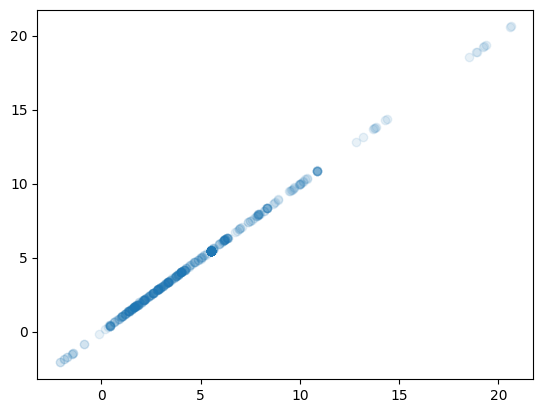

In [6]:
from matplotlib import pyplot as plt
plt.scatter(out[:, :, 36].flatten(), torch_out[:, :, 36].flatten(), alpha=0.1)

Max diff: 0.477
Mean diff: 0.03058


Text(0.5, 1.0, 'Per-token difference between JAX and Torch outputs')

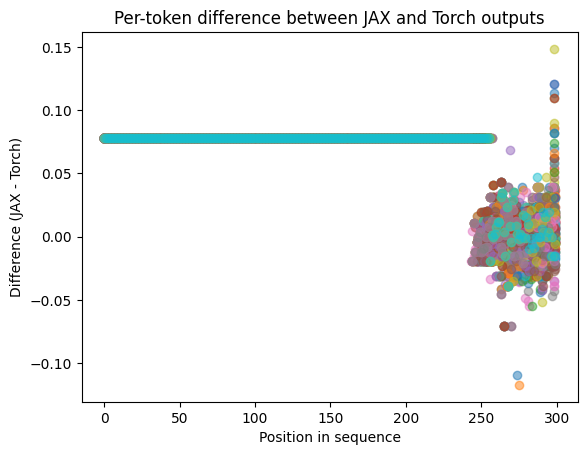

In [8]:
from matplotlib import pyplot as plt

diff = out - torch_out
print("Max diff:", jnp.abs(diff).max())
print("Mean diff:", jnp.abs(diff).mean())
y = diff[:,:,36].reshape(diff.shape[0], -1)
x = np.tile(np.arange(y.shape[-1]), (y.shape[0], 1))
for i in range(x.shape[0]):
    plt.scatter(x[i], y[i], alpha=0.5) 
plt.ylabel("Difference (JAX - Torch)")
plt.xlabel("Position in sequence")
plt.title("Per-token difference between JAX and Torch outputs")

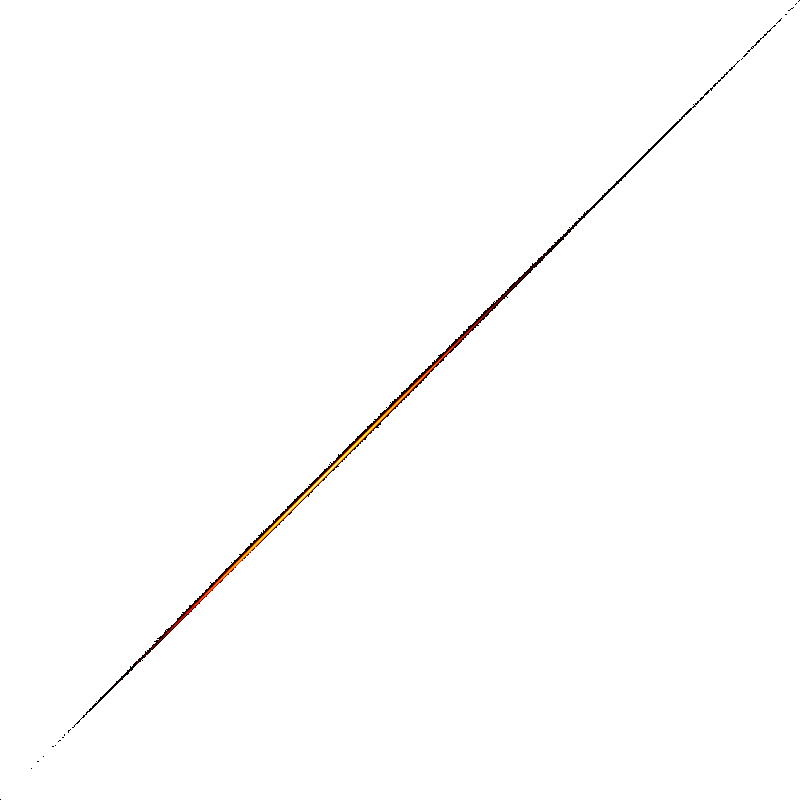

In [7]:
import datashader as ds
import pandas as pd
import colorcet as co

import datashader.transfer_functions as tf

# Prepare data for datashader
df_plot = pd.DataFrame({
    'x': out[:, :, :].flatten().astype(np.float32),
    'y': torch_out[:, :, :].flatten().astype(np.float32)
})

# Create a canvas
canvas = ds.Canvas(plot_width=800, plot_height=800)
agg = canvas.points(df_plot, 'x', 'y')

# Render the image
img = tf.shade(agg, cmap=co.fire, how='eq_hist')
img

In [ ]:
out.shape

(8, 300, 151936)

In [ ]:
import datashader as ds
import pandas as pd
import colorcet
import holoviews as hv
import holoviews.operation.datashader as hd

import datashader.transfer_functions as tf

# Prepare data for datashader
df_plot = pd.DataFrame({
    'x': np.tile(np.arange(0, np.prod(out.shape[1:]), dtype=np.float32), out.shape[0]),
    'y': torch_out[:, :, :].flatten().astype(np.float32) - out[:, :, :].flatten().astype(np.float32)
})

# Create a canvas
canvas = ds.Canvas(plot_width=400, plot_height=400)
agg = canvas.points(df_plot, 'x', 'y', kdims=[('x', 'id'), ('y', "diff")])

# Render the image with dynspread
img = tf.shade(agg, how='eq_hist', cmap=colorcet.fire)
# img = tf.dynspread(img, threshold=0.9, max_px=400)

hv.output(backend='bokeh')
hd.shade(hv.Image(img))

In [38]:

hv.output(backend='bokeh')

hd.shade(hv.Image(agg), cmap=colorcet.fire, width=400, height=400, kdims=[('x', 'id'), ('y', "diff")])


:RGB   [x,y]   (R,G,B,A)

In [31]:
hv.output(backend='bokeh')
datashade = hd.datashade(hv.Points(df_plot, ['x', 'y']), cmap=colorcet.fire, width=400, height=400)
hd.dynspread(datashade, threshold=0.9, max_px=5, how='over').opts(height=400, width=400)

ModuleNotFoundError: No module named 'jupyter_bokeh'

:DynamicMap   []

In [24]:
np.tile(np.arange(0, np.prod((3,4)), dtype=np.float32), 2)

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.,  0.,
        1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.],
      dtype=float32)

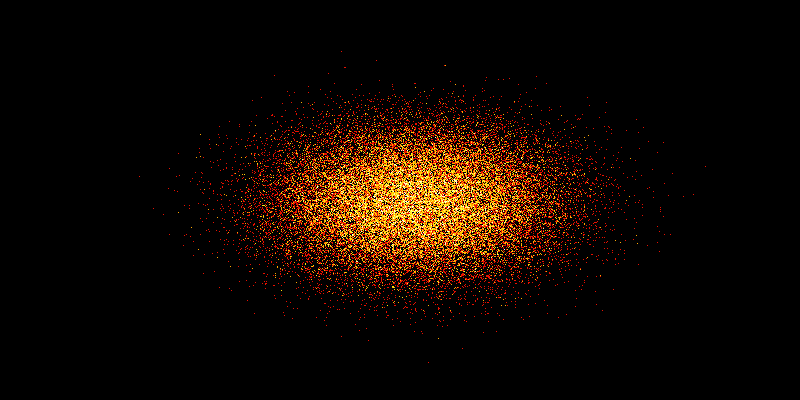

In [60]:
import datashader as ds
import pandas as pd

import datashader.transfer_functions as tf

# Prepare data for datashader
df_plot = pd.DataFrame({
    # 'x': np.arange(0, np.prod(out.shape[1:]), dtype=np.float32).repeat(out.shape[0], axis=0),
    'x': np.random.randn(100000).astype(np.float32),
    'y': np.random.randn(100000).astype(np.float32)
})

# Create a canvas
canvas = ds.Canvas(plot_width=800, plot_height=400)
agg = canvas.points(df_plot, 'x', 'y')

# Render the image

img = ds.tf.set_background(ds.tf.shade(agg, cmap=colorcet.fire), "black")
img = tf.dynspread(img, threshold=0.9, max_px=400)
img

In [44]:
import datashader as ds, pandas as pd, colorcet
df  = pd.read_csv('census.csv')
cvs = ds.Canvas(plot_width=850, plot_height=500)
agg = cvs.points(df, 'longitude', 'latitude')
img = ds.tf.shade(agg, cmap=colorcet.fire, how='log')

FileNotFoundError: [Errno 2] No such file or directory: 'census.csv'